# Marketing Campaign Performance Analysis
## Data cleaning, quality validation & exploratory data analysis (EDA)

**Role:** Analyst workflow / portfolio project  
**Source:** `marketing_campaign_data_messy.csv` — the original 2,020-row, 12-column dataset discussed in the profiling and cleaning work.

### Objectives
1. Preserve the raw source and document every transformation.
2. Resolve structural issues (headers, duplicate records, duplicate Clicks field).
3. standardize text, numeric, spend, status, and date fields without silently inventing values.
4. Keep data-quality flags for issues that cannot be resolved from the data alone.
5. Explore channel, campaign-type, funnel, spend-efficiency, activity, and time performance.
6. Export a cleaned analysis dataset and EDA summary tables for the next dashboard / SQL stage.



## 1. Setup and load the raw data

The original schema includes two columns named `Clicks` (one header has trailing whitespace). We preserve the source as `df_raw`, normalize headers, and explicitly identify the two Clicks fields before deciding how to proceed.

In [1]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Portable input selection: prefer the project-standard filename beside this notebook.
candidate_files = [
    Path("marketing_campaign_data_messy.csv"),
    Path("marketing_campaign_data_messy(20261021-014110).csv"),
    Path("/mnt/data/marketing_campaign_data_messy(20261021-014110).csv"),
]
DATA_FILE = next((path for path in candidate_files if path.exists()), None)
if DATA_FILE is None:
    raise FileNotFoundError(
        "Could not find the raw campaign CSV. Place 'marketing_campaign_data_messy.csv' "
        "in the same folder as this notebook, then rerun."
    )

df_raw = pd.read_csv(DATA_FILE)
print(f"Raw shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
display(df_raw.head())
display(pd.DataFrame({"column": df_raw.columns, "dtype": df_raw.dtypes.astype(str).values}))

Raw shape: 2,020 rows × 12 columns


,Campaign_ID,Campaign_Name,Start_Date,End_Date,Channel,Impressions,Clicks,Spend,Conversions,Active,Clicks,Campaign_Tag
0,CMP-00001,Q4_Summer_CMP-00001,2023-11-24 00:00:00,2023-12-13,TikTok,16795,197,$102.82,20.00,Y,NaN,TI
1,CMP-00002,Q1_Launch_CMP-00002,2023-05-06 00:00:00,2023-05-12,Facebook,1860,30,24.33,1.00,0,NaN,FA
2,CMP-00003,Q3_Winter_CMP-00003,2023-12-13 00:00:00,2023-12-20,Email,77820,843,1323.39,51.00,No,NaN,EM
3,CMP-00004,Q1_BlackFriday_CMP-00004,2023-10-30,2023-11-03,TikTok,55886,2019,2180.38,135.00,True,NaN,TI
4,CMP-00005,Q2_Winter_CMP-00005,2023-04-22 00:00:00,2023-04-23,Facebook,7265,169,252.44,30.00,Yes,NaN,FA


,column,dtype
0,Campaign_ID,object
1,Campaign_Name,object
2,Start_Date,object
3,End_Date,object
4,Channel,object
5,Impressions,int64
6,Clicks,int64
7,Spend,object
8,Conversions,float64
9,Active,object


## 2. Initial profiling and quality baseline

In [2]:
raw_profile = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "non_null": df_raw.notna().sum(),
    "missing": df_raw.isna().sum(),
    "missing_pct": (df_raw.isna().mean() * 100).round(2),
    "unique_non_null": df_raw.nunique(dropna=True)
}).sort_values(["missing", "unique_non_null"], ascending=[False, True])
display(raw_profile)
print("Exact duplicate rows:", int(df_raw.duplicated().sum()))
print("Rows with at least one missing value:", int(df_raw.isna().any(axis=1).sum()))

,dtype,non_null,missing,missing_pct,unique_non_null
Clicks,float64,40,1980,98.02,40
Conversions,float64,1820,200,9.90,528
Channel,object,1919,101,5.00,10
Active,object,2020,0,0.00,7
Campaign_Tag,object,2020,0,0.00,8
End_Date,object,2020,0,0.00,387
Start_Date,object,2020,0,0.00,624
Clicks,int64,2020,0,0.00,1503
Impressions,int64,2020,0,0.00,1983
Spend,object,2020,0,0.00,1993


Exact duplicate rows: 19
Rows with at least one missing value: 1985


## 3. Normalizing headers and inspect the two Clicks columns

The header cleanup removes leading/trailing spaces and normalizes case and separators. Because both Clicks headers normalize to the same name, we assign explicit names based on their original position. The second Clicks column is known to be sparse (40 populated values versus 1,980 missing in the prior profiling); we compare it with the first before excluding it from KPI calculations.

In [3]:
original_columns = list(df_raw.columns)
df = df_raw.copy()

# Rename by source position so duplicate/whitespace headers remain distinguishable.
normalized = [
    re.sub(r"_+", "_", re.sub(r"[^0-9a-zA-Z]+", "_", str(c).strip().lower())).strip("_")
    for c in original_columns
]
seen = {}
unique_names = []
for name in normalized:
    seen[name] = seen.get(name, 0) + 1
    unique_names.append(f"{name}_{seen[name]}" if seen[name] > 1 else name)
df.columns = unique_names

# Expected names from the source schema, with Clicks fields distinguished.
print("Normalized columns:", df.columns.tolist())
click_cols = [c for c in df.columns if c.startswith("clicks")]
if len(click_cols) != 2:
    raise ValueError(f"Expected two Clicks columns; found {click_cols}. Review the source schema.")

# Use a consistent, readable name for the primary source field and the sparse second field.
rename_map = {click_cols[0]: "clicks", click_cols[1]: "clicks_secondary"}
df = df.rename(columns=rename_map)

required = ["campaign_id", "campaign_name", "start_date", "end_date", "channel",
            "impressions", "clicks", "spend", "conversions", "active", "clicks_secondary", "campaign_tag"]
missing_required = [c for c in required if c not in df.columns]
if missing_required:
    raise ValueError(f"Expected source columns not found after normalization: {missing_required}")

clicks_comparison = pd.DataFrame({
    "primary_non_null": [df["clicks"].notna().sum()],
    "secondary_non_null": [df["clicks_secondary"].notna().sum()],
    "both_present": [(df["clicks"].notna() & df["clicks_secondary"].notna()).sum()],
    "equal_when_both_present": [
        (df.loc[df["clicks"].notna() & df["clicks_secondary"].notna(), "clicks"]
         == df.loc[df["clicks"].notna() & df["clicks_secondary"].notna(), "clicks_secondary"]).mean()
    ]
})
display(clicks_comparison)
display(df.loc[df["clicks_secondary"].notna(),
               ["campaign_id", "clicks", "clicks_secondary"]].head(20))

Normalized columns: ['campaign_id', 'campaign_name', 'start_date', 'end_date', 'channel', 'impressions', 'clicks', 'spend', 'conversions', 'active', 'clicks_2', 'campaign_tag']


,primary_non_null,secondary_non_null,both_present,equal_when_both_present
0,2020,40,40,0.00


,campaign_id,clicks,clicks_secondary
22,CMP-00023,2637,"86,385.00"
43,CMP-00044,2149,"81,075.00"
63,CMP-00064,2164,"78,213.00"
88,CMP-00089,3125,"87,884.00"
139,CMP-00140,4574,"92,026.00"
143,CMP-00144,350,"24,436.00"
156,CMP-00157,2912,"82,765.00"
200,CMP-00201,2185,"69,935.00"
288,CMP-00289,406,"16,169.00"
305,CMP-00306,92,"3,228.00"


### Clicks-field decision

The main `clicks` field is retained for analysis because it is the primary field used in the existing profiling work. The sparse `clicks_secondary` field is retained in the audit copy and excluded from KPIs unless source documentation proves it should replace or supplement the primary field. This avoids silently merging two potentially different measures.

## 4. Campaign ID duplicates: exact duplicates versus conflicting records

In [4]:
# Inspecting repeated IDs before deduplication.
id_counts = df["campaign_id"].astype("string").str.strip().value_counts(dropna=False)
repeated_ids = id_counts[id_counts > 1]
print("Repeated Campaign_ID values:", len(repeated_ids))
print("Rows associated with repeated IDs:", int(repeated_ids.sum()) if len(repeated_ids) else 0)

df["campaign_id"] = df["campaign_id"].astype("string").str.strip()
exact_duplicate_mask = df.duplicated(keep="first")
print("Exact duplicate rows:", int(exact_duplicate_mask.sum()))

duplicate_id_rows = df[df["campaign_id"].duplicated(keep=False)].sort_values("campaign_id")
display(duplicate_id_rows.head(50))

Repeated Campaign_ID values: 20
Rows associated with repeated IDs: 40
Exact duplicate rows: 19


,campaign_id,campaign_name,start_date,end_date,channel,impressions,clicks,spend,conversions,active,clicks_secondary,campaign_tag
184,CMP-00185,Q3_Launch_CMP-00185,2023-08-03 00:00:00,2023-08-27,Facebok,56016,1728,1890.33,128.00,No,NaN,FA
2014,CMP-00185,Q3_Launch_CMP-00185,2023-08-03 00:00:00,2023-08-27,Facebok,56016,1728,1890.33,128.00,No,NaN,FA
387,CMP-00388,Q1_Summer_CMP-00388,2023-06-20 00:00:00,2023-06-25,TikTok,57958,2328,$2135.23,280.00,Y,NaN,TI
2013,CMP-00388,Q1_Summer_CMP-00388,2023-06-20 00:00:00,2023-06-25,TikTok,57958,2328,$2135.23,280.00,Y,NaN,TI
399,CMP-00400,Q3_Summer_CMP-00400,2023-10-31 00:00:00,2023-11-13,TikTok,30592,586,$503.95,77.00,1,NaN,TI
2015,CMP-00400,Q3_Summer_CMP-00400,2023-10-31 00:00:00,2023-11-13,TikTok,30592,586,$503.95,77.00,1,NaN,TI
438,CMP-00439,Q1_Launch_CMP-00439,2023-08-03 00:00:00,2023-08-27,Google Ads,88235,3182,5093.82,385.00,1,NaN,GO
2010,CMP-00439,Q1_Launch_CMP-00439,2023-08-03 00:00:00,2023-08-27,Google Ads,88235,3182,5093.82,385.00,1,NaN,GO
2011,CMP-01028,Q4_Summer_CMP-01028,2023-12-24 00:00:00,2024-01-05,TikTok,54441,2158,$2422.76,252.00,Yes,NaN,TI
1027,CMP-01028,Q4_Summer_CMP-01028,2023-12-24 00:00:00,2024-01-05,TikTok,54441,2158,$2422.76,252.00,Yes,NaN,TI


**Decision rule:** remove exact duplicate rows; for non-identical rows sharing a Campaign_ID, do not blindly keep the first. The earlier review found 20 repeated IDs and a specific `CMP-01377` campaign-tag discrepancy; inspect the group before applying a documented resolution. The following code preserves a conflict report and uses the source's first row only after marking the issue for review. Adjust the resolution if your record-level comparison indicates a different trusted row.

In [6]:
# Keeping a durable audit table before changing row counts.
duplicate_id_audit = (
    df[df["campaign_id"].duplicated(keep=False)]
    .sort_values("campaign_id")
    .copy()
)
duplicate_id_audit.to_csv("campaign_id_duplicate_audit.csv", index=False)

# Removing only full-row duplicates first.
rows_before_exact_dedup = len(df)
df = df.drop_duplicates().copy()
print("Exact duplicate rows removed:", rows_before_exact_dedup - len(df))

# Special case previously investigated in the project:
# CMP-01377's duplicate rows differed only in Campaign_Tag; channel/tag pattern supports EM for Email.
if "CMP-01377" in set(df["campaign_id"].dropna()):
    df.loc[df["campaign_id"].eq("CMP-01377"), "campaign_tag"] = (
        df.loc[df["campaign_id"].eq("CMP-01377"), "channel"]
          .astype("string").str.strip().map({"Email": "EM", "E-mail": "EM"}).fillna(df.loc[df["campaign_id"].eq("CMP-01377"), "campaign_tag"])
    )

# If IDs still repeat, report all conflicting groups and retain one record per ID for campaign-level analysis.
# This is an explicit campaign-grain choice; the full audit remains in duplicate_id_audit.
remaining_dup_ids = df["campaign_id"].duplicated(keep=False)
conflicting_id_report = df.loc[remaining_dup_ids].sort_values("campaign_id").copy()
print("Rows still belonging to repeated Campaign_IDs:", len(conflicting_id_report))
display(conflicting_id_report.head(30))

df_campaign = df.drop_duplicates(subset="campaign_id", keep="first").copy()
print(f"Campaign-grain dataset: {len(df_campaign):,} rows; unique IDs: {df_campaign['campaign_id'].nunique():,}")

Exact duplicate rows removed: 1
Rows still belonging to repeated Campaign_IDs: 0


,campaign_id,campaign_name,start_date,end_date,channel,impressions,clicks,spend,conversions,active,clicks_secondary,campaign_tag


Campaign-grain dataset: 2,000 rows; unique IDs: 2,000


## 5. Standardizing text fields and derive campaign type

Text is trimmed and standardized where safe. Missing channels are labelled `Unknown` for grouping (the original null state is preserved in a flag). `campaign_type` is derived from the second underscore-delimited token in `campaign_name`, matching the existing project approach; rows that do not follow this naming convention remain `Unknown`.

In [8]:
df_clean = df_campaign.copy()

text_cols = ["campaign_id", "campaign_name", "channel", "active", "campaign_tag"]
for col in text_cols:
    df_clean[col] = df_clean[col].astype("string").str.strip()
    df_clean[col] = df_clean[col].replace({"": pd.NA, "nan": pd.NA, "None": pd.NA})

# Preserving the source category before standardizing known, unambiguous variants.
df_clean["channel_raw"] = df_clean["channel"]
df_clean["channel_was_missing"] = df_clean["channel"].isna()

# Exact alias mapping only: these values are clear spelling/format variants of known channels.
channel_aliases = {
    "e-mail": "Email",
    "facebok": "Facebook",
    "gogle": "Google Ads",
    "insta_gram": "Instagram",
    "tik_tok": "TikTok",
}
channel_key = df_clean["channel"].astype("string").str.strip().str.lower()
df_clean["channel"] = channel_key.map(channel_aliases).fillna(
    df_clean["channel"].astype("string").str.strip()
)
df_clean["channel"] = df_clean["channel"].replace({"": pd.NA, "nan": pd.NA}).fillna("Unknown")

display(pd.DataFrame({
    "source_channel_value": sorted(df_clean["channel_raw"].dropna().astype(str).unique()),
    "note": "Review channel_aliases above for exact standardization decisions"
}).head(20))

df_clean["campaign_type"] = (
    df_clean["campaign_name"].str.split("_").str[1].str.strip().replace("", pd.NA).fillna("Unknown")
)

# Campaign tag cleanup based on observed channel/tag mappings from the project.
df_clean["campaign_tag_raw"] = df_clean["campaign_tag"]
df_clean["campaign_tag"] = df_clean["campaign_tag"].str.upper()
df_clean["campaign_tag"] = df_clean["campaign_tag"].replace({"E-": "EM", "INVALID": pd.NA, "XX": pd.NA})
channel_to_tag = {"Email": "EM", "Facebook": "FA", "Google Ads": "GO", "Instagram": "IN", "TikTok": "TI"}
invalid_tag_mask = df_clean["campaign_tag"].isna()
mapped_tags = df_clean.loc[invalid_tag_mask, "channel"].map(channel_to_tag)
df_clean.loc[invalid_tag_mask, "campaign_tag"] = mapped_tags
df_clean["campaign_tag"] = df_clean["campaign_tag"].fillna("Unknown")
df_clean["campaign_tag_was_unresolved"] = df_clean["campaign_tag"].eq("Unknown")

display(df_clean[["campaign_name", "campaign_type", "channel", "campaign_tag_raw", "campaign_tag"]].head(15))
display(pd.crosstab(df_clean["campaign_tag"], df_clean["channel"], dropna=False))

,source_channel_value,note
0,E-mail,Review channel_aliases above for exact standar...
1,Email,Review channel_aliases above for exact standar...
2,Facebok,Review channel_aliases above for exact standar...
3,Facebook,Review channel_aliases above for exact standar...
4,Gogle,Review channel_aliases above for exact standar...
5,Google Ads,Review channel_aliases above for exact standar...
6,Insta_gram,Review channel_aliases above for exact standar...
7,Instagram,Review channel_aliases above for exact standar...
8,TikTok,Review channel_aliases above for exact standar...
9,Tik_Tok,Review channel_aliases above for exact standar...


,campaign_name,campaign_type,channel,campaign_tag_raw,campaign_tag
0,Q4_Summer_CMP-00001,Summer,TikTok,TI,TI
1,Q1_Launch_CMP-00002,Launch,Facebook,FA,FA
2,Q3_Winter_CMP-00003,Winter,Email,EM,EM
3,Q1_BlackFriday_CMP-00004,BlackFriday,TikTok,TI,TI
4,Q2_Winter_CMP-00005,Winter,Facebook,FA,FA
5,Q4_BlackFriday_CMP-00006,BlackFriday,Instagram,IN,IN
6,Q3_Launch_CMP-00007,Launch,Facebook,FA,FA
7,Q4_Launch_CMP-00008,Launch,Instagram,IN,IN
8,Q4_BlackFriday_CMP-00009,BlackFriday,Google Ads,GO,GO
9,Q2_Winter_CMP-00010,Winter,Email,EM,EM


channel,Email,Facebook,Google Ads,Instagram,TikTok,Unknown
campaign_tag,,,,,,
EM,375,0,0,0,0,0
FA,0,401,0,0,0,0
GO,0,0,354,0,0,0
IN,0,0,0,358,0,0
TI,0,0,0,0,412,0
Unknown,0,0,0,0,0,100


**Tag policy:** `E-` is standardized to `EM`; `INVALID` and `XX` are not assumed to mean a particular channel unless the channel-to-tag mapping supports it. Missing channel records cannot be reliably mapped from channel alone and remain `Unknown`. Raw tags are preserved in `campaign_tag_raw`.

## 6. Normalizing Active status

In [9]:
df_clean["active_raw"] = df_clean["active"]
active_map = {
    "Y": "Yes", "YES": "Yes", "TRUE": "Yes", "1": "Yes",
    "N": "No", "NO": "No", "FALSE": "No", "0": "No"
}
df_clean["active"] = (
    df_clean["active"].str.upper().map(active_map).fillna("Unknown")
)
display(df_clean["active"].value_counts(dropna=False).rename_axis("active_status").to_frame("campaigns"))

,campaigns
active_status,
Yes,1182
No,818


## 7. Numeric fields and spend cleaning

In [10]:
# Convert count/volume fields without silently replacing failures with zero.
numeric_fields = ["impressions", "clicks", "conversions"]
for col in numeric_fields:
    df_clean[f"{col}_raw"] = df_clean[col]
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# Preserve source spend as text for audit; parse currency symbols, commas and whitespace.
df_clean["spend_raw"] = df_clean["spend"]
spend_text = df_clean["spend"].astype("string").str.strip()
spend_text = spend_text.str.replace(",", "", regex=False)
# Keep digits, decimal point, and minus sign; currency symbols are stripped.
spend_numeric_text = spend_text.str.replace(r"[^0-9.\-]", "", regex=True)
df_clean["spend_numeric"] = pd.to_numeric(spend_numeric_text, errors="coerce")

# Flags distinguish source missingness, parsing failure and negative numeric values.
df_clean["spend_source_missing_flag"] = df_clean["spend_raw"].isna()
df_clean["spend_parse_failure_flag"] = df_clean["spend_raw"].notna() & df_clean["spend_numeric"].isna()
df_clean["negative_spend_flag"] = df_clean["spend_numeric"] < 0

# Negative spend is not changed to zero or absolute value without source documentation.
# Exclude it from cost-efficiency KPIs, but retain its parsed value and a flag.
df_clean["spend_analysis"] = df_clean["spend_numeric"].where(df_clean["spend_numeric"] >= 0, np.nan)

numeric_quality = pd.DataFrame({
    "field": ["impressions", "clicks", "conversions", "spend"],
    "parsed_non_null": [df_clean[c].notna().sum() for c in numeric_fields] + [df_clean["spend_numeric"].notna().sum()],
    "missing_or_parse_failed": [df_clean[c].isna().sum() for c in numeric_fields] + [df_clean["spend_numeric"].isna().sum()],
})
display(numeric_quality)
print("Spend parse failures:", int(df_clean["spend_parse_failure_flag"].sum()))
print("Negative spend records:", int(df_clean["negative_spend_flag"].sum()))
display(df_clean.loc[df_clean["spend_parse_failure_flag"] | df_clean["negative_spend_flag"],
                     ["campaign_id", "spend_raw", "spend_numeric", "spend_parse_failure_flag", "negative_spend_flag"]].head(30))

,field,parsed_non_null,missing_or_parse_failed
0,impressions,2000,0
1,clicks,2000,0
2,conversions,1800,200
3,spend,2000,0


Spend parse failures: 0
Negative spend records: 19


,campaign_id,spend_raw,spend_numeric,spend_parse_failure_flag,negative_spend_flag
144,CMP-00145,-1407.54,"-1,407.54",False,True
407,CMP-00408,-1214.52,"-1,214.52",False,True
576,CMP-00577,-821.8,-821.80,False,True
604,CMP-00605,-942.8,-942.80,False,True
676,CMP-00677,-1640.88,"-1,640.88",False,True
817,CMP-00818,-1261.81,"-1,261.81",False,True
886,CMP-00887,-2162.5,"-2,162.50",False,True
924,CMP-00925,-648.3,-648.30,False,True
1125,CMP-01126,-122.8,-122.80,False,True
1142,CMP-01143,-20.05,-20.05,False,True


### Spend interpretation note

The dataset contains mixed currency/text representations and negative values. Parsing strips formatting symbols and commas, but it does **not** convert currencies. Negative spend is flagged and excluded from cost KPIs pending source confirmation; the raw value is retained.

## 8. Standardizing dates conservatively

In [11]:
def parse_campaign_date(value):
    """Parse known unambiguous patterns; return NaT for unresolved/invalid values."""
    if pd.isna(value):
        return pd.NaT
    s = str(value).strip()
    s = re.sub(r"\s+00:00:00$", "", s)
    # ISO-like dates and year-first slash dates are unambiguous.
    for fmt in ("%Y-%m-%d", "%Y/%m/%d", "%Y-%m-%d %H:%M:%S"):
        try:
            return pd.to_datetime(s, format=fmt, errors="raise")
        except (ValueError, TypeError):
            pass
    # Explicit day-first patterns observed in the project.
    for fmt in ("%d/%m/%Y", "%d-%m-%Y", "%d-%b-%Y", "%d-%B-%Y"):
        try:
            return pd.to_datetime(s, format=fmt, errors="raise")
        except (ValueError, TypeError):
            pass
    # Month-first formats are only accepted if the first component cannot be a day (>12).
    # If both components <= 12, the value is ambiguous and deliberately left unresolved.
    m = re.fullmatch(r"(\d{1,2})/(\d{1,2})/(\d{4})", s)
    if m:
        a, b, y = map(int, m.groups())
        if a > 12 and b <= 12:  # clearly day/month/year
            return pd.to_datetime(s, format="%d/%m/%Y", errors="coerce")
        if b > 12 and a <= 12:  # clearly month/day/year
            return pd.to_datetime(s, format="%m/%d/%Y", errors="coerce")
        return pd.NaT
    return pd.NaT

for col in ["start_date", "end_date"]:
    df_clean[f"{col}_raw"] = df_clean[col]
    df_clean[col] = df_clean[col].map(parse_campaign_date)

df_clean["start_date_parse_failed_flag"] = df_clean["start_date_raw"].notna() & df_clean["start_date"].isna()
df_clean["end_date_parse_failed_flag"] = df_clean["end_date_raw"].notna() & df_clean["end_date"].isna()
df_clean["invalid_date_order_flag"] = (
    df_clean["start_date"].notna() & df_clean["end_date"].notna() &
    (df_clean["end_date"] < df_clean["start_date"])
)
df_clean["campaign_duration_days"] = (df_clean["end_date"] - df_clean["start_date"]).dt.days
df_clean["valid_duration_flag"] = (
    df_clean["campaign_duration_days"].notna() & (df_clean["campaign_duration_days"] >= 0)
)

date_quality = pd.DataFrame({
    "check": ["Start date parse failures", "End date parse failures", "End before start", "Valid non-negative duration"],
    "records": [
        int(df_clean["start_date_parse_failed_flag"].sum()),
        int(df_clean["end_date_parse_failed_flag"].sum()),
        int(df_clean["invalid_date_order_flag"].sum()),
        int(df_clean["valid_duration_flag"].sum())
    ]
})
display(date_quality)
display(df_clean.loc[df_clean["invalid_date_order_flag"],
                     ["campaign_id", "campaign_name", "start_date_raw", "end_date_raw",
                      "start_date", "end_date", "campaign_duration_days"]].head(30))

,check,records
0,Start date parse failures,0
1,End date parse failures,0
2,End before start,78
3,Valid non-negative duration,1922


,campaign_id,campaign_name,start_date_raw,end_date_raw,start_date,end_date,campaign_duration_days
23,CMP-00024,Q4_Winter_CMP-00024,2023-05-06 00:00:00,2023-05-01,2023-05-06,2023-05-01,-5
54,CMP-00055,Q1_Launch_CMP-00055,2023-09-01 00:00:00,2023-08-27,2023-09-01,2023-08-27,-5
71,CMP-00072,Q1_Summer_CMP-00072,2023-02-01 00:00:00,2023-01-27,2023-02-01,2023-01-27,-5
124,CMP-00125,Q4_Summer_CMP-00125,2023-04-01,2023-02-02,2023-04-01,2023-02-02,-58
156,CMP-00157,Q3_Launch_CMP-00157,2023-12-06 00:00:00,2023-12-01,2023-12-06,2023-12-01,-5
195,CMP-00196,Q4_Summer_CMP-00196,2023-08-04,2023-04-21,2023-08-04,2023-04-21,-105
200,CMP-00201,Q3_BlackFriday_CMP-00201,2023-01-11 00:00:00,2023-01-06,2023-01-11,2023-01-06,-5
218,CMP-00219,Q3_Winter_CMP-00219,2023-10-03 00:00:00,2023-09-28,2023-10-03,2023-09-28,-5
221,CMP-00222,Q1_Winter_CMP-00222,2023-08-26 00:00:00,2023-08-21,2023-08-26,2023-08-21,-5
241,CMP-00242,Q4_Summer_CMP-00242,2023-10-01,2023-01-11,2023-10-01,2023-01-11,-263


**Date policy:** ambiguous slash dates are not guessed. `start_date_raw` and `end_date_raw` preserve source strings; parse failures and reversed date order remain flagged. Campaign duration is only used for records with successfully parsed dates and non-negative duration. The previously observed 78 reversed date pairs should be rechecked after this conservative parsing.

## 9. Funnel and data-quality validation

In [12]:
# Flags preserve impossible or suspicious relationships for investigation.
df_clean["negative_impressions_flag"] = df_clean["impressions"] < 0
df_clean["negative_clicks_flag"] = df_clean["clicks"] < 0
df_clean["negative_conversions_flag"] = df_clean["conversions"] < 0
df_clean["clicks_gt_impressions_flag"] = (
    df_clean["clicks"].notna() & df_clean["impressions"].notna() &
    (df_clean["clicks"] > df_clean["impressions"])
)
df_clean["conversions_gt_clicks_flag"] = (
    df_clean["conversions"].notna() & df_clean["clicks"].notna() &
    (df_clean["conversions"] > df_clean["clicks"])
)
df_clean["conversion_missing_flag"] = df_clean["conversions"].isna()

quality_checks = pd.DataFrame({
    "check": [
        "Missing channel in source", "Unknown channel after standardization",
        "Unknown campaign tag", "Spend parse failure", "Negative spend",
        "Clicks > impressions", "Conversions > clicks",
        "Missing conversions", "Invalid date order", "Start date parse failure",
        "End date parse failure", "Negative impressions", "Negative clicks", "Negative conversions"
    ],
    "records": [
        int(df_clean["channel_was_missing"].sum()),
        int(df_clean["channel"].eq("Unknown").sum()),
        int(df_clean["campaign_tag"].eq("Unknown").sum()),
        int(df_clean["spend_parse_failure_flag"].sum()),
        int(df_clean["negative_spend_flag"].sum()),
        int(df_clean["clicks_gt_impressions_flag"].sum()),
        int(df_clean["conversions_gt_clicks_flag"].sum()),
        int(df_clean["conversion_missing_flag"].sum()),
        int(df_clean["invalid_date_order_flag"].sum()),
        int(df_clean["start_date_parse_failed_flag"].sum()),
        int(df_clean["end_date_parse_failed_flag"].sum()),
        int(df_clean["negative_impressions_flag"].sum()),
        int(df_clean["negative_clicks_flag"].sum()),
        int(df_clean["negative_conversions_flag"].sum())
    ]
})
quality_checks["pct_of_campaigns"] = (quality_checks["records"] / len(df_clean) * 100).round(2)
display(quality_checks.sort_values("records", ascending=False))

,check,records,pct_of_campaigns
7,Missing conversions,200,10.00
0,Missing channel in source,100,5.00
2,Unknown campaign tag,100,5.00
1,Unknown channel after standardization,100,5.00
8,Invalid date order,78,3.90
4,Negative spend,19,0.95
5,Clicks > impressions,0,0.00
3,Spend parse failure,0,0.00
6,Conversions > clicks,0,0.00
9,Start date parse failure,0,0.00


## 10. Building campaign-level marketing KPIs

Rates are calculated at campaign level for drill-down, but channel performance is calculated from **summed numerators and denominators**, not the average of campaign-level rates. Spend efficiency is calculated only where spend is non-negative and the denominator is positive.

In [13]:
df_clean["ctr"] = np.where(
    df_clean["impressions"] > 0,
    df_clean["clicks"] / df_clean["impressions"],
    np.nan
)
df_clean["conversion_rate"] = np.where(
    df_clean["clicks"] > 0,
    df_clean["conversions"] / df_clean["clicks"],
    np.nan
)
df_clean["cpc"] = np.where(
    df_clean["clicks"] > 0,
    df_clean["spend_analysis"] / df_clean["clicks"],
    np.nan
)
df_clean["cost_per_conversion"] = np.where(
    df_clean["conversions"] > 0,
    df_clean["spend_analysis"] / df_clean["conversions"],
    np.nan
)
df_clean["funnel_valid_flag"] = (
    df_clean["impressions"].ge(0) & df_clean["clicks"].ge(0) &
    df_clean["conversions"].ge(0) &
    ~df_clean["clicks_gt_impressions_flag"] &
    ~df_clean["conversions_gt_clicks_flag"]
)
display(df_clean[["campaign_id", "impressions", "clicks", "conversions", "spend_analysis",
                  "ctr", "conversion_rate", "cpc", "cost_per_conversion", "funnel_valid_flag"]].head())

,campaign_id,impressions,clicks,conversions,spend_analysis,ctr,conversion_rate,cpc,cost_per_conversion,funnel_valid_flag
0,CMP-00001,16795,197,20.00,102.82,0.01,0.10,0.52,5.14,True
1,CMP-00002,1860,30,1.00,24.33,0.02,0.03,0.81,24.33,True
2,CMP-00003,77820,843,51.00,"1,323.39",0.01,0.06,1.57,25.95,True
3,CMP-00004,55886,2019,135.00,"2,180.38",0.04,0.07,1.08,16.15,True
4,CMP-00005,7265,169,30.00,252.44,0.02,0.18,1.49,8.41,True


## 11. EDA - channel performance

In [14]:
channel_performance = (
    df_clean.groupby("channel", dropna=False)
    .agg(
        campaigns=("campaign_id", "nunique"),
        impressions=("impressions", "sum"),
        clicks=("clicks", "sum"),
        conversions=("conversions", "sum"),
        spend=("spend_analysis", "sum"),
        campaigns_with_conversion_data=("conversions", "count"),
        campaigns_with_valid_spend=("spend_analysis", "count")
    )
    .reset_index()
)
channel_performance["ctr_pct"] = channel_performance["clicks"] / channel_performance["impressions"].replace(0, np.nan) * 100
channel_performance["conversion_rate_pct"] = channel_performance["conversions"] / channel_performance["clicks"].replace(0, np.nan) * 100
channel_performance["cpc"] = channel_performance["spend"] / channel_performance["clicks"].replace(0, np.nan)
channel_performance["cost_per_conversion"] = channel_performance["spend"] / channel_performance["conversions"].replace(0, np.nan)
channel_performance = channel_performance.round({
    "spend": 2, "ctr_pct": 2, "conversion_rate_pct": 2, "cpc": 2, "cost_per_conversion": 2
})
display(channel_performance.sort_values("spend", ascending=False))

,channel,campaigns,impressions,clicks,conversions,spend,campaigns_with_conversion_data,campaigns_with_valid_spend,ctr_pct,conversion_rate_pct,cpc,cost_per_conversion
0,Email,375,19156770,560082,"62,632.00","2,197,742.66",341,373,2.92,11.18,3.92,35.09
1,Facebook,401,20395140,623589,"69,502.00","1,776,485.52",362,394,3.06,11.15,2.85,25.56
4,TikTok,412,20528411,617274,"67,713.00","770,686.97",372,408,3.01,10.97,1.25,11.38
2,Google Ads,354,17646113,533706,"60,384.00","682,094.12",319,351,3.02,11.31,1.28,11.30
3,Instagram,358,17331450,517158,"57,088.00","635,386.13",314,357,2.98,11.04,1.23,11.13
5,Unknown,100,4642169,150666,"17,744.00","172,413.96",92,98,3.25,11.78,1.14,9.72


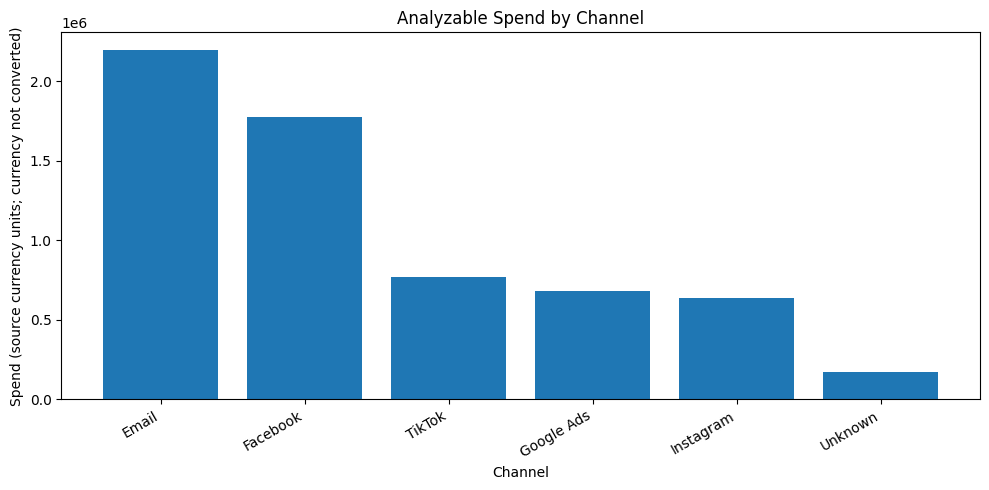

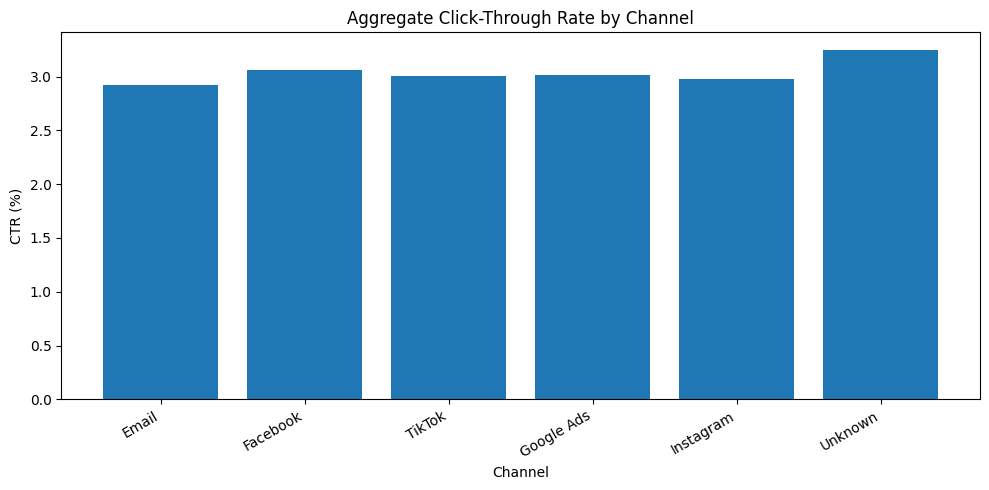

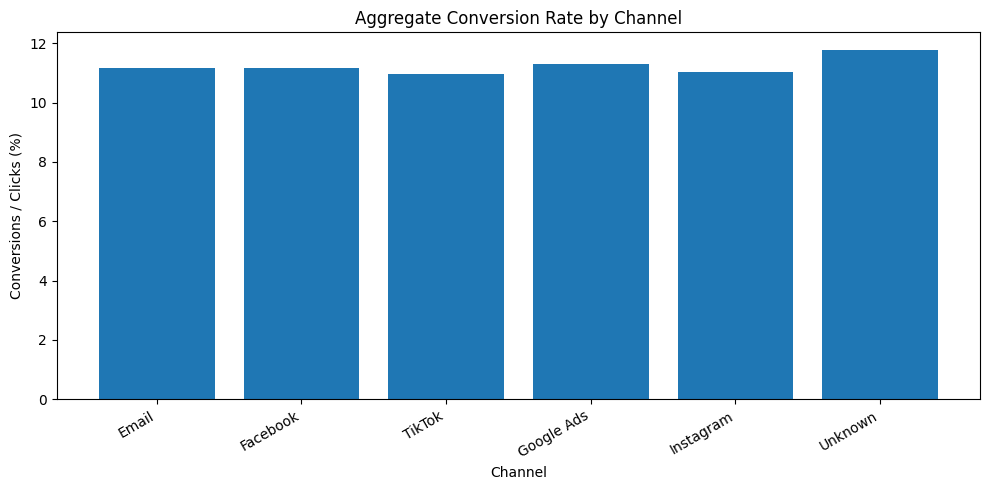

In [16]:
# Spending by channel
plot_data = channel_performance.sort_values("spend", ascending=False)
plt.figure(figsize=(10, 5))
plt.bar(plot_data["channel"].astype(str), plot_data["spend"])
plt.title("Analyzable Spend by Channel")
plt.xlabel("Channel")
plt.ylabel("Spend (source currency units; currency not converted)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# Aggregating funnel rates by channel
plt.figure(figsize=(10, 5))
plt.bar(plot_data["channel"].astype(str), plot_data["ctr_pct"])
plt.title("Aggregate Click-Through Rate by Channel")
plt.xlabel("Channel")
plt.ylabel("CTR (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(plot_data["channel"].astype(str), plot_data["conversion_rate_pct"])
plt.title("Aggregate Conversion Rate by Channel")
plt.xlabel("Channel")
plt.ylabel("Conversions / Clicks (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 12. EDA - campaign type and active status

In [17]:
campaign_type_performance = (
    df_clean.groupby("campaign_type", dropna=False)
    .agg(
        campaigns=("campaign_id", "nunique"),
        impressions=("impressions", "sum"),
        clicks=("clicks", "sum"),
        conversions=("conversions", "sum"),
        spend=("spend_analysis", "sum"),
        median_duration_days=("campaign_duration_days", "median")
    )
    .reset_index()
)
campaign_type_performance["ctr_pct"] = campaign_type_performance["clicks"] / campaign_type_performance["impressions"].replace(0, np.nan) * 100
campaign_type_performance["conversion_rate_pct"] = campaign_type_performance["conversions"] / campaign_type_performance["clicks"].replace(0, np.nan) * 100
campaign_type_performance["cost_per_conversion"] = campaign_type_performance["spend"] / campaign_type_performance["conversions"].replace(0, np.nan)
display(campaign_type_performance.round(2).sort_values("conversions", ascending=False))

active_summary = (
    df_clean.groupby("active", dropna=False)
    .agg(campaigns=("campaign_id", "nunique"),
         impressions=("impressions", "sum"),
         clicks=("clicks", "sum"),
         conversions=("conversions", "sum"),
         spend=("spend_analysis", "sum"))
    .reset_index()
)
display(active_summary)

,campaign_type,campaigns,impressions,clicks,conversions,spend,median_duration_days,ctr_pct,conversion_rate_pct,cost_per_conversion
1,Launch,506,24496756,744030,"86,477.00","1,906,544.97",15.00,3.04,11.62,22.05
3,Winter,512,25445867,767167,"85,047.00","1,443,321.40",16.00,3.01,11.09,16.97
0,BlackFriday,503,25492225,763194,"82,282.00","963,778.01",15.00,2.99,10.78,11.71
2,Summer,479,24265205,728084,"81,257.00","1,921,164.98",14.00,3.00,11.16,23.64


,active,campaigns,impressions,clicks,conversions,spend
0,No,818,40985493,1228350,"136,452.00","3,534,280.51"
1,Yes,1182,58714560,1774125,"198,611.00","2,700,528.85"


## 13. EDA - spend distribution and outlier investigation

,spend_analysis
count,"1,981.00"
mean,"3,147.30"
std,"25,050.17"
min,10.01
1%,34.53
5%,149.77
25%,659.42
50%,"1,455.43"
75%,"2,653.78"
95%,"5,308.23"


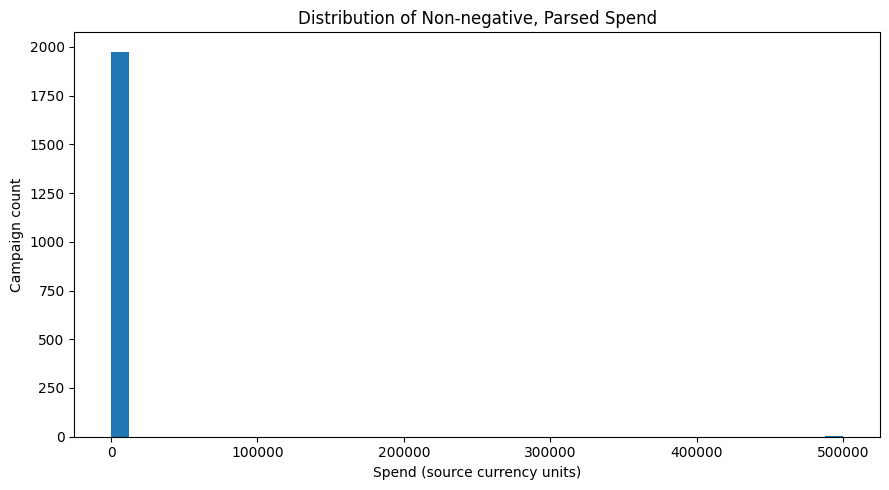

Upper IQR fence: 5,645.32; flagged campaigns: 73


,campaign_id,campaign_name,channel,spend_raw,spend_analysis
789,CMP-00790,Q2_Summer_CMP-00790,Facebook,500000.0,"500,000.00"
1460,CMP-01461,Q4_Launch_CMP-01461,Facebook,500000.0,"500,000.00"
1781,CMP-01782,Q1_Launch_CMP-01782,Email,500000.0,"500,000.00"
1754,CMP-01755,Q1_Summer_CMP-01755,Email,500000.0,"500,000.00"
1718,CMP-01719,Q1_Winter_CMP-01719,Email,500000.0,"500,000.00"
1443,CMP-01444,Q1_Launch_CMP-01444,Google Ads,8921.51,"8,921.51"
1925,CMP-01926,Q4_Winter_CMP-01926,Facebook,8269.9,"8,269.90"
1358,CMP-01359,Q3_BlackFriday_CMP-01359,TikTok,8267.84,"8,267.84"
1449,CMP-01450,Q4_Summer_CMP-01450,Google Ads,8209.43,"8,209.43"
189,CMP-00190,Q4_Summer_CMP-00190,Facebook,$7777.24,"7,777.24"


In [18]:
spend_valid = df_clean["spend_analysis"].dropna()
display(spend_valid.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).to_frame("spend_analysis"))

plt.figure(figsize=(9, 5))
plt.hist(spend_valid, bins=40)
plt.title("Distribution of Non-negative, Parsed Spend")
plt.xlabel("Spend (source currency units)")
plt.ylabel("Campaign count")
plt.tight_layout()
plt.show()

# IQR candidates are investigation flags, not automatic deletions.
q1, q3 = spend_valid.quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
spend_outliers = df_clean.loc[df_clean["spend_analysis"] > upper_fence,
                              ["campaign_id", "campaign_name", "channel", "spend_raw", "spend_analysis"]].sort_values("spend_analysis", ascending=False)
print(f"Upper IQR fence: {upper_fence:,.2f}; flagged campaigns: {len(spend_outliers):,}")
display(spend_outliers.head(25))

## 14. EDA - date coverage and campaign duration

,metric,value
0,Earliest valid start date,2023-01-01 00:00:00
1,Latest valid start date,2024-01-01 00:00:00
2,Earliest valid end date,2022-12-31 00:00:00
3,Latest valid end date,2024-01-30 00:00:00
4,Median valid campaign duration (days),16.00


,campaign_type,campaigns,median_days,mean_days,max_days
0,BlackFriday,482,16.00,16.66,285
3,Winter,487,16.00,18.92,258
1,Launch,491,15.00,16.45,278
2,Summer,462,15.00,16.07,239


,start_month,campaigns,impressions,clicks,conversions,spend
0,2023-01-01,143,7204271,230776,"25,181.00","780,450.17"
1,2023-02-01,159,7704150,223278,"25,945.00","269,588.58"
2,2023-03-01,159,7911343,243134,"27,847.00","304,978.70"
3,2023-04-01,148,7493051,232859,"26,985.00","296,540.99"
4,2023-05-01,169,8373467,253625,"28,211.00","803,030.09"
5,2023-06-01,182,9344389,276968,"31,138.00","834,630.98"
6,2023-07-01,167,8848368,273040,"30,241.00","352,694.82"
7,2023-08-01,162,7453594,214297,"24,176.00","280,597.75"
8,2023-09-01,160,7720097,239445,"26,440.00","786,021.83"
9,2023-10-01,186,8786025,247354,"26,797.00","307,394.58"


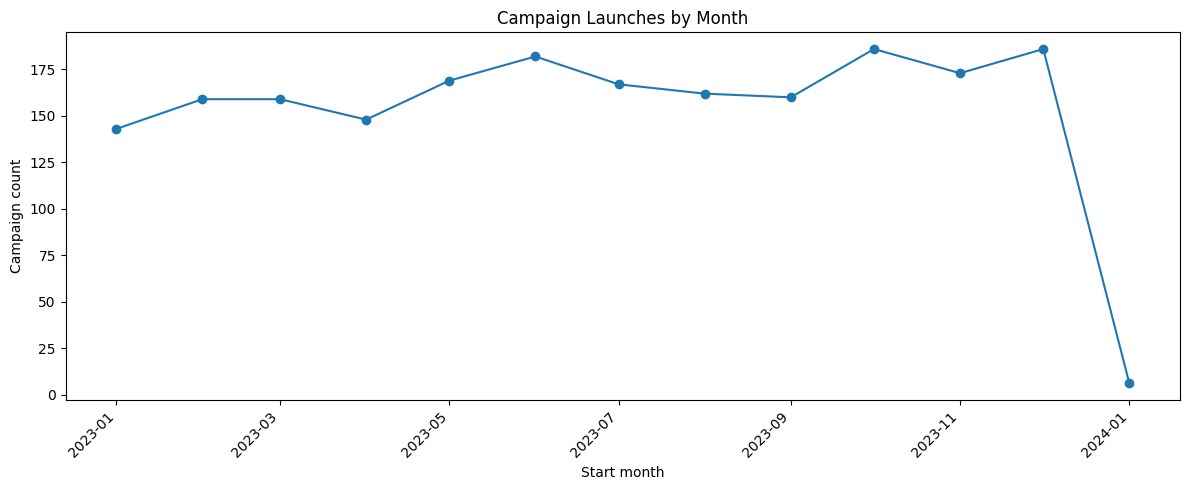

In [19]:
date_coverage = pd.DataFrame({
    "metric": ["Earliest valid start date", "Latest valid start date",
               "Earliest valid end date", "Latest valid end date",
               "Median valid campaign duration (days)"],
    "value": [
        df_clean["start_date"].min(),
        df_clean["start_date"].max(),
        df_clean["end_date"].min(),
        df_clean["end_date"].max(),
        df_clean.loc[df_clean["valid_duration_flag"], "campaign_duration_days"].median()
    ]
})
display(date_coverage)

duration_by_type = (
    df_clean.loc[df_clean["valid_duration_flag"]]
    .groupby("campaign_type")["campaign_duration_days"]
    .agg(campaigns="count", median_days="median", mean_days="mean", max_days="max")
    .reset_index()
    .sort_values("median_days", ascending=False)
)
display(duration_by_type.round(2))

# Monthly trend is descriptive only; it uses campaign start month and is not daily attribution.
monthly_launches = (
    df_clean.dropna(subset=["start_date"])
    .assign(start_month=lambda x: x["start_date"].dt.to_period("M").dt.to_timestamp())
    .groupby("start_month")
    .agg(campaigns=("campaign_id", "nunique"),
         impressions=("impressions", "sum"),
         clicks=("clicks", "sum"),
         conversions=("conversions", "sum"),
         spend=("spend_analysis", "sum"))
    .reset_index()
)
display(monthly_launches.head(20))
if not monthly_launches.empty:
    plt.figure(figsize=(12, 5))
    plt.plot(monthly_launches["start_month"], monthly_launches["campaigns"], marker="o")
    plt.title("Campaign Launches by Month")
    plt.xlabel("Start month")
    plt.ylabel("Campaign count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

## 15. EDA - missing conversions and funnel anomalies

In [20]:
missing_conversion_by_channel = (
    df_clean.groupby("channel", dropna=False)["conversion_missing_flag"]
    .agg(campaigns="size", missing_conversions="sum", missing_rate="mean")
    .reset_index()
)
missing_conversion_by_channel["missing_rate_pct"] = missing_conversion_by_channel["missing_rate"] * 100
display(missing_conversion_by_channel.round(2).sort_values("missing_rate_pct", ascending=False))

funnel_anomaly_records = df_clean.loc[
    df_clean["clicks_gt_impressions_flag"] | df_clean["conversions_gt_clicks_flag"] |
    df_clean["negative_impressions_flag"] | df_clean["negative_clicks_flag"] |
    df_clean["negative_conversions_flag"],
    ["campaign_id", "campaign_name", "channel", "impressions", "clicks", "conversions",
     "clicks_gt_impressions_flag", "conversions_gt_clicks_flag",
     "negative_impressions_flag", "negative_clicks_flag", "negative_conversions_flag"]
].copy()
print("Campaigns with at least one funnel/negative-count anomaly:", len(funnel_anomaly_records))
display(funnel_anomaly_records.head(50))

,channel,campaigns,missing_conversions,missing_rate,missing_rate_pct
3,Instagram,358,44,0.12,12.29
2,Google Ads,354,35,0.10,9.89
1,Facebook,401,39,0.10,9.73
4,TikTok,412,40,0.10,9.71
0,Email,375,34,0.09,9.07
5,Unknown,100,8,0.08,8.00


Campaigns with at least one funnel/negative-count anomaly: 0


,campaign_id,campaign_name,channel,impressions,clicks,conversions,clicks_gt_impressions_flag,conversions_gt_clicks_flag,negative_impressions_flag,negative_clicks_flag,negative_conversions_flag


## 16. Results-driven executive summary

The following cell generates a concise readout from the cleaned campaign-grain dataset. Treat these as descriptive findings, not proof of causality or incremental lift. Spend is analyzed only where parsing succeeded and spend is non-negative; 19 negative values are retained in the audit fields but excluded from cost-efficiency metrics. Currency comparability is not assumed.

In [21]:
# Results-driven summary: all values below are computed from the loaded source data.
total_campaigns = int(df_clean["campaign_id"].nunique())
missing_conversion_count = int(df_clean["conversion_missing_flag"].sum())
missing_conversion_pct = missing_conversion_count / len(df_clean) * 100
unknown_channel_count = int(df_clean["channel"].eq("Unknown").sum())
invalid_date_order_count = int(df_clean["invalid_date_order_flag"].sum())
negative_spend_count = int(df_clean["negative_spend_flag"].sum())
spend_outlier_count = int(df_clean["spend_iqr_outlier_flag"].sum()) if "spend_iqr_outlier_flag" in df_clean else int(len(spend_outliers))

known_channels = channel_performance[channel_performance["channel"].ne("Unknown")]
best_ctr = known_channels.dropna(subset=["ctr_pct"]).sort_values("ctr_pct", ascending=False).head(1)
best_cvr = known_channels.dropna(subset=["conversion_rate_pct"]).sort_values("conversion_rate_pct", ascending=False).head(1)
best_cpa = known_channels.dropna(subset=["cost_per_conversion"]).sort_values("cost_per_conversion", ascending=True).head(1)
most_conversions = channel_performance.sort_values("conversions", ascending=False).head(1)
best_type_cpa = campaign_type_performance.dropna(subset=["cost_per_conversion"]).sort_values("cost_per_conversion").head(1)

def first_value(frame, column):
    return frame.iloc[0][column] if len(frame) else "Not available"

executive_summary = pd.DataFrame([
    {"area": "Campaign grain", "finding": f"{total_campaigns:,} unique campaigns after removing exact duplicates and resolving the single documented conflicting-ID case."},
    {"area": "Missing conversions", "finding": f"{missing_conversion_count:,} campaigns ({missing_conversion_pct:.2f}%) have missing conversions; they are not treated as zero."},
    {"area": "Unknown channel", "finding": f"{unknown_channel_count:,} campaigns remain Unknown after standardizing exact spelling variants; source values are retained in channel_raw."},
    {"area": "Date quality", "finding": f"{invalid_date_order_count:,} campaigns have an end date earlier than the start date; these durations should not be used as valid durations."},
    {"area": "Negative spend", "finding": f"{negative_spend_count:,} negative spend values are retained for review and excluded from cost-efficiency KPIs."},
    {"area": "Highest aggregate CTR", "finding": f"{first_value(best_ctr, 'channel')} ({first_value(best_ctr, 'ctr_pct'):.2f}% CTR)." if len(best_ctr) else "Not available."},
    {"area": "Highest aggregate conversion rate", "finding": f"{first_value(best_cvr, 'channel')} ({first_value(best_cvr, 'conversion_rate_pct'):.2f}% conversion rate)." if len(best_cvr) else "Not available."},
    {"area": "Lowest aggregate cost per conversion", "finding": f"{first_value(best_cpa, 'channel')} ({first_value(best_cpa, 'cost_per_conversion'):.2f} spend units per conversion)." if len(best_cpa) else "Not available."},
    {"area": "Most conversions by channel", "finding": f"{first_value(most_conversions, 'channel')} ({first_value(most_conversions, 'conversions'):,.0f} recorded conversions; missing conversion values excluded from the sum)." if len(most_conversions) else "Not available."},
    {"area": "Lowest campaign-type cost per conversion", "finding": f"{first_value(best_type_cpa, 'campaign_type')} ({first_value(best_type_cpa, 'cost_per_conversion'):.2f} spend units per conversion)." if len(best_type_cpa) else "Not available."},
])
display(executive_summary)


,area,finding
0,Campaign grain,"2,000 unique campaigns after removing exact du..."
1,Missing conversions,200 campaigns (10.00%) have missing conversion...
2,Unknown channel,100 campaigns remain Unknown after standardizi...
3,Date quality,78 campaigns have an end date earlier than the...
4,Negative spend,19 negative spend values are retained for revi...
5,Highest aggregate CTR,Facebook (3.06% CTR).
6,Highest aggregate conversion rate,Google Ads (11.31% conversion rate).
7,Lowest aggregate cost per conversion,Instagram (11.13 spend units per conversion).
8,Most conversions by channel,"Facebook (69,502 recorded conversions; missing..."
9,Lowest campaign-type cost per conversion,BlackFriday (11.71 spend units per conversion).


## 18. Exporting clean data, quality report, and EDA summaries

In [22]:
# Drop no audit fields by default: raw fields and quality flags are useful for review.
df_clean.to_csv("marketing_campaign_cleaned_for_analysis.csv", index=False)
quality_checks.to_csv("marketing_campaign_data_quality_report.csv", index=False)
channel_performance.to_csv("marketing_campaign_eda_channel_performance.csv", index=False)
campaign_type_performance.to_csv("marketing_campaign_eda_campaign_type_performance.csv", index=False)
monthly_launches.to_csv("marketing_campaign_eda_monthly_launches.csv", index=False)
funnel_anomaly_records.to_csv("marketing_campaign_funnel_anomalies.csv", index=False)
spend_outliers.to_csv("marketing_campaign_spend_outlier_review.csv", index=False)

print("Exported:")
for filename in [
    "marketing_campaign_cleaned_for_analysis.csv",
    "marketing_campaign_data_quality_report.csv",
    "marketing_campaign_eda_channel_performance.csv",
    "marketing_campaign_eda_campaign_type_performance.csv",
    "marketing_campaign_eda_monthly_launches.csv",
    "marketing_campaign_funnel_anomalies.csv",
    "marketing_campaign_spend_outlier_review.csv",
    "campaign_id_duplicate_audit.csv",
]:
    print(" •", filename)

Exported:
 • marketing_campaign_cleaned_for_analysis.csv
 • marketing_campaign_data_quality_report.csv
 • marketing_campaign_eda_channel_performance.csv
 • marketing_campaign_eda_campaign_type_performance.csv
 • marketing_campaign_eda_monthly_launches.csv
 • marketing_campaign_funnel_anomalies.csv
 • marketing_campaign_spend_outlier_review.csv
 • campaign_id_duplicate_audit.csv
